In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()

In [ ]:
print(cancer.keys())
print(cancer.data.shape) # 입력항목 : 30개
print(cancer.feature_names)
print(cancer.target_names) # 응답값은 악성(0)이냐 아니냐(1)

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
(569, 30)
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
['malignant' 'benign']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

x = cancer.data
y = cancer.target

# 학습 데이터 분리
# test_size 는 기본값이 0.25 이다.
# stratify=y : y 값을 기준으로 공평하게 섞는다.
x_train, x_test, y_train, y_test = train_test_split(x,y, random_state=33, stratify=y)

# 알고리즘 학습 및 선택
model = KNeighborsClassifier(n_neighbors=2).fit(x_train, y_train)

# 모델 테스트 및 점수 결과
score = model.score(x_test, y_test)
print(f'score : {score:.2f}')

score : 0.90


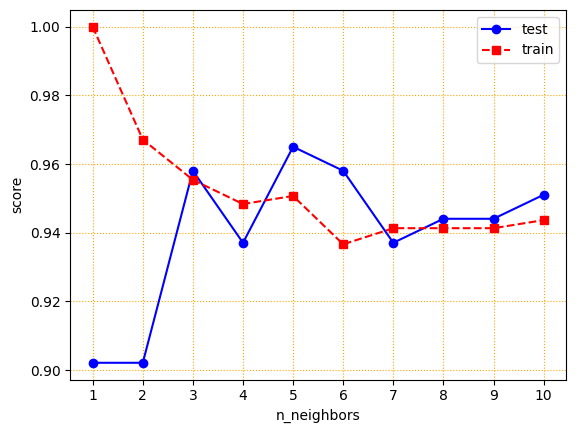

In [ ]:
import matplotlib.pyplot as plt

n_neighbors = range(1,11)
scores = []
scores_train = []

for n in n_neighbors:
  model = KNeighborsClassifier(n_neighbors=n).fit(x_train, y_train)
  score = model.score(x_test, y_test)
  scores.append(score)

  score = model.score(x_train, y_train)
  scores_train.append(score)

plt.plot(n_neighbors, scores, 'bo-', label='test')
plt.plot(n_neighbors, scores_train, 'rs--', label='train')
plt.grid(True, color='orange', linestyle=':')
plt.xticks(n_neighbors)
plt.xlabel('n_neighbors')
plt.ylabel('score')
plt.legend()
plt.show()